# 04 · Modelado con redes: CNN desde cero y transfer learning

**Fase 4 de CRISP-DM.** Red convolucional pequeña entrenada desde cero sobre la fruta recortada en
fondo blanco (notebook 02, §4). Este notebook **lee los resultados guardados**; para regenerarlos:

```bash
python -m src.training.train --model cnn_search   # 5 configuraciones → experiments/results/cnn_busqueda*.json
python -m src.training.train --model cnn_stable   # 4 configuraciones estables (en Colab con GPU: notebooks/colab_entrenar_cnn)
python -m src.training.train --model cnn          # solo la configuración por defecto (CNN_DEFAULT)
python -m src.training.train --model tl_busqueda       # 2.ª iteración: transfer learning (Colab)
python -m src.training.train --model tl_entre_fuentes  # 2.ª iteración: generalización entre fuentes (Colab)
python -m src.training.train --model v3                # 3.ª iteración: etiquetas revisadas (Colab)
python -m src.training.train --model v4                # 4.ª iteración: solo 3 frutas (Colab)
```

Secciones 1–6: CNN desde cero (1.ª iteración). Secciones 7–9: las iteraciones posteriores, y la 10
resume **todos** los entrenamientos.

Mismo protocolo que los modelos clásicos: entrena con `train`, se elige con `val`. Detalle en
`docs/crisp-dm.md` §4.2.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

from src import config  # noqa: E402
from src.models.cnn import CNN_DEFAULT, CNN_GRID, build_cnn  # noqa: E402

pd.set_option("display.precision", 3)
NAMES = ["Base", "Sin aumento de datos", "Red pequeña", "Más regularización", "Tasa de aprendizaje 3e-4"]
runs = [json.load(open(config.RESULTS_DIR / f"cnn_busqueda_{i}.json", encoding="utf-8")) for i in range(len(CNN_GRID))]
histories = [pd.read_csv(config.LOGS_DIR / f"cnn_busqueda_{i}_historia.csv") for i in range(len(CNN_GRID))]

## 1. Arquitectura

Normalización a [0, 1] y aumento de datos van **dentro del modelo** (el aumento solo actúa al
entrenar). Bloques Conv-BatchNorm-ReLU-MaxPool y GlobalAveragePooling en lugar de Flatten para
tener pocos parámetros.

In [2]:
print(CNN_DEFAULT)
build_cnn().summary()

{'filters': (32, 64, 128, 192), 'dense': 128, 'dropout': 0.4, 'lr': 0.001, 'l2': 0.0001, 'augment': True, 'batch_size': 32, 'schedule': 'plateau', 'weight_power': 1.0}


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 128, 128, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_translation              │ (None, 128, 128, 3)    │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_brightness               │ (None, 128, 128, 3)    │             0 │
│ (RandomBrightness)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_contrast                 │ (None, 128, 128, 3)    │             0 │
│ (RandomContrast)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 192)    │       221,184 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 192)    │           768 │
│ (BatchNormalization)            │                        │             

 Total params: 340,963 (1.30 MB)

 Trainable params: 340,131 (1.30 MB)

 Non-trainable params: 832 (3.25 KB)

### Aumento de datos

Ejemplo: la misma imagen de entrenamiento pasada 6 veces por las capas de aumento (volteos,
rotación, zoom, traslación con relleno blanco, brillo y contraste ±10 %).

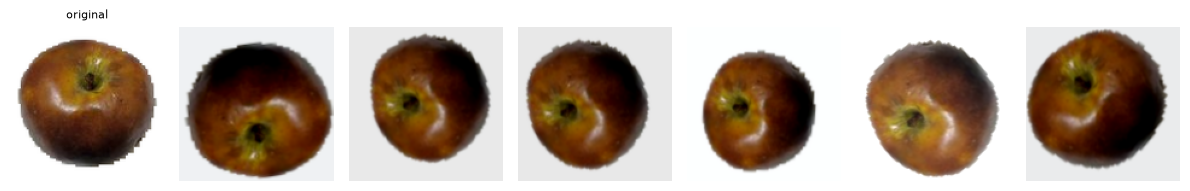

In [3]:
import tensorflow as tf  # noqa: E402

from src.data.preprocess import load_split  # noqa: E402

model = build_cnn()
augment = tf.keras.Sequential([layer for layer in model.layers if layer.name.startswith("random_")])
X_tr, rows_tr = load_split("train")
sample = X_tr[[i for i, r in enumerate(rows_tr) if r["calidad"] == "Podrida"][0]][None]
fig, axes = plt.subplots(1, 7, figsize=(12, 2))
axes[0].imshow(sample[0])
axes[0].set_title("original", fontsize=8)
for ax in axes[1:]:
    ax.imshow(np.clip(augment(sample / 255.0, training=True)[0].numpy(), 0, 1))
for ax in axes:
    ax.set_axis_off()
plt.tight_layout()

## 2. Búsqueda de configuraciones

Una variación a la vez sobre la configuración base. Cada corrida conserva la época con mejor
F1-macro en validación (máx. 40 épocas, parada tras 8 sin mejorar).

In [4]:
pd.DataFrame([{
    "configuración": NAMES[i], "cambios": CNN_GRID[i] or "—", "parámetros": r["parametros"], "épocas": r["epocas"],
    "F1 train": r["train"]["f1_macro"], "F1 val": r["val"]["f1_macro"],
    "F1 val Kaggle": r["val"]["por_fuente"]["kaggle"], "F1 val HDF": r["val"]["por_fuente"]["hdf"],
    "recall Podrida": r["val"]["por_clase"]["Podrida"]["recall"],
} for i, r in enumerate(runs)])

,configuración,cambios,parámetros,épocas,F1 train,F1 val,F1 val Kaggle,F1 val HDF,recall Podrida
0,Base,—,340963,37,0.886,0.867,0.712,0.858,0.914
1,Sin aumento de datos,{'augment': False},340963,40,0.926,0.891,0.773,0.877,0.880
2,Red pequeña,"{'filters': (16, 32, 64, 96), 'dense': 64}",86003,37,0.790,0.846,0.722,0.833,0.927
3,Más regularización,"{'dropout': 0.6, 'l2': 0.0005}",340963,29,0.848,0.814,0.721,0.793,0.753
4,Tasa de aprendizaje 3e-4,{'lr': 0.0003},340963,32,0.869,0.857,0.683,0.870,0.865


## 3. Curvas de entrenamiento

Pérdida de entrenamiento y F1-macro de validación por época. La línea punteada es el SVM (mejor
modelo clásico).

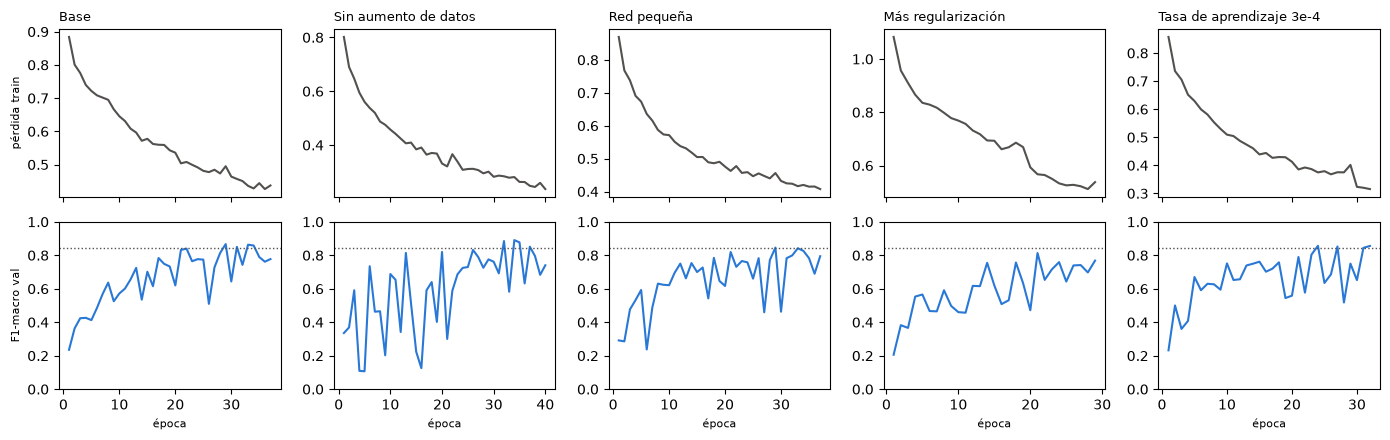

In [5]:
svm = json.load(open(config.RESULTS_DIR / "classic.json", encoding="utf-8"))["svm"]["val"]["f1_macro"]
fig, axes = plt.subplots(2, len(runs), figsize=(14, 4.5), sharex="col")
for i, h in enumerate(histories):
    epochs = h["epoca"] + 1
    axes[0, i].plot(epochs, h["loss"], color="#52514e", lw=1.5)
    axes[0, i].set_title(NAMES[i], fontsize=9, loc="left")
    axes[1, i].plot(epochs, h["val_f1_macro"], color="#2a78d6", lw=1.5)
    axes[1, i].axhline(svm, color="#52514e", ls=":", lw=1)
    axes[1, i].set_ylim(0, 1)
    axes[1, i].set_xlabel("época", fontsize=8)
axes[0, 0].set_ylabel("pérdida train", fontsize=8)
axes[1, 0].set_ylabel("F1-macro val", fontsize=8)
plt.tight_layout()

**Entrenamiento inestable:** el F1 de validación oscila ±0,1 entre épocas consecutivas en todas las
configuraciones, aunque la pérdida de entrenamiento baja de forma suave. Como se elige la mejor de
~35 épocas ruidosas con la propia validación, el F1 de validación de la CNN es **optimista** y las
diferencias entre configuraciones (0,81–0,89) no son concluyentes. La cifra fiable sale del
conjunto de prueba (Fase 5).

In [6]:
osc = pd.DataFrame({
    "configuración": NAMES,
    "mejor época": [int(h["val_f1_macro"].idxmax()) + 1 for h in histories],
    "F1 val máx.": [h["val_f1_macro"].max() for h in histories],
    "F1 val media últimas 10": [h["val_f1_macro"].tail(10).mean() for h in histories],
    "desv. últimas 10": [h["val_f1_macro"].tail(10).std() for h in histories],
})
osc

,configuración,mejor época,F1 val máx.,F1 val media últimas 10,desv. últimas 10
0,Base,29,0.867,0.797,0.070
1,Sin aumento de datos,34,0.891,0.763,0.113
2,Red pequeña,29,0.846,0.760,0.113
3,Más regularización,21,0.814,0.700,0.096
4,Tasa de aprendizaje 3e-4,24,0.857,0.745,0.118


## 4. Mejor configuración vs. SVM

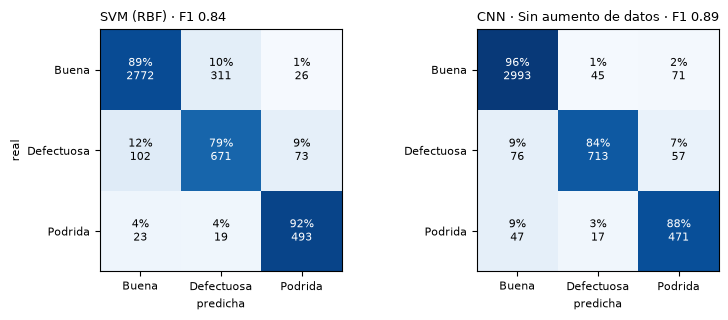

In [7]:
best = int(np.argmax([r["val"]["f1_macro"] for r in runs]))
classic = json.load(open(config.RESULTS_DIR / "classic.json", encoding="utf-8"))
panels = [("SVM (RBF)", classic["svm"]["val"]), (f"CNN · {NAMES[best]}", runs[best]["val"])]
fig, axes = plt.subplots(1, 2, figsize=(8, 3.3))
for ax, (title, res) in zip(axes, panels):
    cm = np.array(res["matriz_confusion"])
    frac = cm / cm.sum(1, keepdims=True)
    ax.imshow(frac, cmap="Blues", vmin=0, vmax=1)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f"{frac[i, j]:.0%}\n{cm[i, j]}", ha="center", va="center", fontsize=8,
                    color="white" if frac[i, j] > 0.55 else "black")
    ax.set_xticks(range(3), config.QUALITY_CLASSES, fontsize=8)
    ax.set_yticks(range(3), config.QUALITY_CLASSES, fontsize=8)
    ax.set_title(f"{title} · F1 {res['f1_macro']:.2f}", fontsize=9, loc="left")
    ax.set_xlabel("predicha", fontsize=8)
axes[0].set_ylabel("real", fontsize=8)
plt.tight_layout()

In [8]:
pd.concat({"SVM": pd.DataFrame(classic["svm"]["val"]["por_clase"]).T,
           f"CNN · {NAMES[best]}": pd.DataFrame(runs[best]["val"]["por_clase"]).T})

precision  recall     f1
SVM                        Buena           0.957   0.892  0.923
                           Defectuosa      0.670   0.793  0.727
                           Podrida         0.833   0.921  0.875
CNN · Sin aumento de datos Buena           0.961   0.963  0.962
                           Defectuosa      0.920   0.843  0.880
                           Podrida         0.786   0.880  0.831

- La CNN supera al SVM en F1-macro de validación, pero la ventaja viene de HDF; en Kaggle queda por
  debajo.
- El error más costoso (Podrida → Buena) es mayor en la CNN (9 % vs. 4 %) y su recall de Podrida no
  cumple la meta de 0,90.
- Pendiente: estabilizar el entrenamiento antes de fijar la configuración final (§5).

## 5. Estabilización (Colab, GPU T4)

Cambios: lotes de **128** y tasa de aprendizaje con **decaimiento coseno** hasta 0 en 40 épocas,
sin parada temprana (`CNN_GRID_STABLE` en `src/models/cnn.py`). Además del F1 de la mejor época se
mira la **media de las últimas 5 épocas**, que no depende de elegir una época con la propia
validación. El IC95 se calcula remuestreando grupos (`src/evaluation/evaluate.py`).

In [9]:
from src.models.cnn import CNN_GRID_STABLE  # noqa: E402

STABLE_NAMES = ["Lote 128 + coseno", "Sin aumento de datos", "Pesos 1/√grupo", "Pesos 1/√grupo, lr 2e-3"]
stable = [json.load(open(config.RESULTS_DIR / f"cnn_estable_{i}.json", encoding="utf-8")) for i in range(len(CNN_GRID_STABLE))]
stable_hist = [pd.read_csv(config.LOGS_DIR / f"cnn_estable_{i}_historia.csv") for i in range(len(CNN_GRID_STABLE))]
stable_eval = [json.load(open(config.RESULTS_DIR / f"eval_cnn_estable_{i}_val.json", encoding="utf-8")) for i in range(len(CNN_GRID_STABLE))]
pd.DataFrame([{
    "configuración": STABLE_NAMES[i], "mejor época": r["mejor_epoca"], "minutos (T4)": r["minutos"],
    "F1 val": r["val"]["f1_macro"], "IC95": "[{:.2f}, {:.2f}]".format(*e["ic95"]["f1_macro"]),
    "últimas 5 media": r["f1_val_ultimas_5_media"], "últimas 5 desv.": r["f1_val_ultimas_5_desv"],
    "F1 val Kaggle": r["val"]["por_fuente"]["kaggle"], "F1 val HDF": r["val"]["por_fuente"]["hdf"],
    "recall Podrida": r["val"]["por_clase"]["Podrida"]["recall"],
} for i, (r, e) in enumerate(zip(stable, stable_eval))])

,configuración,mejor época,minutos (T4),F1 val,IC95,últimas 5 media,últimas 5 desv.,F1 val Kaggle,F1 val HDF,recall Podrida
0,Lote 128 + coseno,36,9.4,0.876,"[0.82, 0.91]",0.870,0.004,0.742,0.868,0.847
1,Sin aumento de datos,30,4.7,0.913,"[0.85, 0.95]",0.890,0.007,0.830,0.901,0.942
2,Pesos 1/√grupo,40,9.3,0.881,"[0.82, 0.92]",0.879,0.002,0.719,0.875,0.880
3,"Pesos 1/√grupo, lr 2e-3",35,9.0,0.890,"[0.80, 0.94]",0.884,0.002,0.736,0.884,0.912


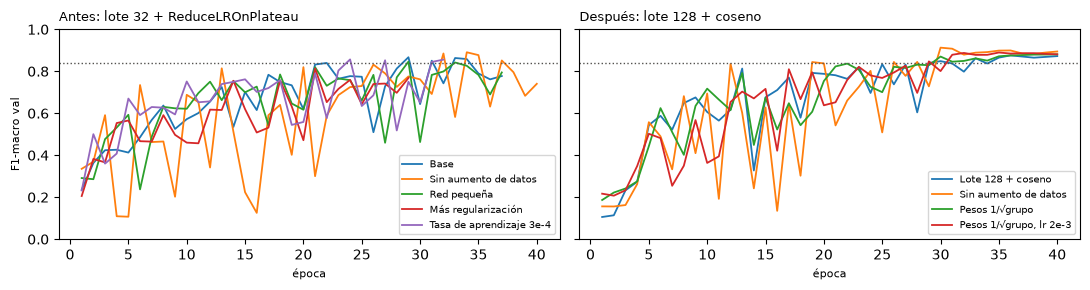

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3), sharey=True)
for ax, hists, names, title in [(axes[0], histories, NAMES, "Antes: lote 32 + ReduceLROnPlateau"),
                                (axes[1], stable_hist, STABLE_NAMES, "Después: lote 128 + coseno")]:
    for h, n in zip(hists, names):
        ax.plot(h["epoca"] + 1, h["val_f1_macro"], lw=1.3, label=n)
    ax.axhline(svm, color="#52514e", ls=":", lw=1)
    ax.set_title(title, fontsize=9, loc="left")
    ax.set_xlabel("época", fontsize=8)
    ax.set_ylim(0, 1)
    ax.legend(fontsize=7, loc="lower right")
axes[0].set_ylabel("F1-macro val", fontsize=8)
plt.tight_layout()

Con el decaimiento coseno el F1 converge: en las últimas 5 épocas varía ±0,002–0,007 (antes ±0,1),
y la mejor época queda a ≤ 0,02 de la media final. **Sin aumento de datos** vuelve a ser la mejor
configuración, ahora también en Kaggle (0,83 vs. 0,79 del SVM).

## 6. Selección del modelo final

Diferencia pareada (mismas imágenes de validación, bootstrap por grupos): si el IC95 no contiene
0, la diferencia no se explica por el azar de qué frutas cayeron en validación.

In [11]:
from src.evaluation.evaluate import f1_macro, paired_diff_ci, predict, recall_of  # noqa: E402

y, pred_final, rows_val = predict(config.FINAL_MODEL, "val")
groups = [r["grupo"] for r in rows_val]
rivals = {"SVM": predict("svm", "val")[1],
          **{STABLE_NAMES[i]: predict(f"cnn_estable_{i}", "val")[1] for i in (0, 2, 3)}}
pd.DataFrame([{"frente a": k, "métrica": m, **dict(zip(["diferencia", "IC95 inf.", "IC95 sup."],
                                                       paired_diff_ci(y, pred_final, p, groups, fn)))}
              for k, p in rivals.items()
              for m, fn in [("F1-macro", f1_macro), ("recall Podrida", recall_of(2))]])

/Users/srengifo/Desktop/fruit-quality-classification/.venv/lib/python3.12/site-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam', because it has 33 variables whereas the saved optimizer has 37 variables. 
  saveable.load_own_variables(store)
I0000 00:00:1795559505.206339  363009 service.cc:153] XLA service 0x6000019cc700 initialized for platform Host (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1795559505.206350  363009 service.cc:161]   StreamExecutor [0]: Host, Default Version (Driver: 0.0.0; Runtime: 0.0.0; Toolkit: 0.0.0; DNN: 0.0.0)
I0000 00:00:1795559505.210180  363009 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.


W0000 00:00:1795559505.303402  363144 cpp_gen_intrinsics.cc:74] Empty bitcode string provided for eigen. Optimizations relying on this IR will be disabled.
I0000 00:00:1795559505.303448  363144 rsqrt.cc:179] Falling back to 1 / sqrt(x) for f32 false
I0000 00:00:1795559505.330344  363009 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


/Users/srengifo/Desktop/fruit-quality-classification/.venv/lib/python3.12/site-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam', because it has 33 variables whereas the saved optimizer has 37 variables. 
  saveable.load_own_variables(store)


,frente a,métrica,diferencia,IC95 inf.,IC95 sup.
0,SVM,F1-macro,0.071,9.048e-03,0.124
1,SVM,recall Podrida,0.021,-9.929e-03,0.065
2,Lote 128 + coseno,F1-macro,0.037,1.215e-02,0.063
3,Lote 128 + coseno,recall Podrida,0.095,5.392e-02,0.148
4,Pesos 1/√grupo,F1-macro,0.032,5.752e-03,0.067
5,Pesos 1/√grupo,recall Podrida,0.062,2.941e-02,0.109
6,"Pesos 1/√grupo, lr 2e-3",F1-macro,0.023,6.504e-06,0.050
7,"Pesos 1/√grupo, lr 2e-3",recall Podrida,0.030,-1.895e-03,0.077


**Modelo final: `cnn_estable_1`** (lote 128, coseno, sin aumento; `config.FINAL_MODEL`). Supera al
SVM en F1-macro con diferencia significativa y empata en recall de Podrida; el SVM se mantiene como
comparación. La elección se registró antes de abrir `test` (`docs/crisp-dm.md` §4.3).

## 7. Segunda iteración: transfer learning (EfficientNetB0)

Con las fotos propias la CNN cayó a F1 0,49 (cambio de dominio, `05_evaluation` §4). Segunda
iteración (`docs/crisp-dm.md` §4.5): **EfficientNetB0** preentrenada en ImageNet, 3 épocas de cabeza
con la base congelada + 15 de ajuste fino (coseno desde 1e-4), y **FruQ** como fuente solo de
entrenamiento. Búsqueda `tl_busqueda` (5 configuraciones, Colab T4). Criterio fijado antes de
entrenar: validación **y** generalización entre fuentes.

In [12]:
from src.models import transfer  # noqa: E402

TL_NAMES = ["Sin aumento", "Aumento geométrico", "Aumento de color", "+ FruQ", "Color + FruQ"]


def load_run(name: str) -> dict:
    return json.load(open(config.RESULTS_DIR / f"{name}.json", encoding="utf-8"))


def run_row(name: str, label: str) -> dict:
    r = load_run(name)
    return {"configuración": label, "épocas": r["epocas"], "mejor época": r["mejor_epoca"],
            "F1 train": r["train"]["f1_macro"], "F1 val": r["val"]["f1_macro"],
            "media últimas 5": r["f1_val_ultimas_5_media"], "recall Podrida val": r["val"]["por_clase"]["Podrida"]["recall"],
            "parámetros": r["parametros"], "minutos": r["minutos"]}


tl = pd.DataFrame([run_row("cnn_estable_1", "CNN desde cero (referencia)")] +
                  [run_row(f"tl_busqueda_{i}", n) for i, n in enumerate(TL_NAMES)]).set_index("configuración")
tl

,épocas,mejor época,F1 train,F1 val,media últimas 5,recall Podrida val,parámetros,minutos
configuración,,,,,,,,
CNN desde cero (referencia),40,30,0.906,0.913,0.890,0.942,340963,4.7
Sin aumento,18,13,0.904,0.904,0.902,0.955,4053414,10.1
Aumento geométrico,18,13,0.865,0.904,0.899,0.931,4053414,14.0
Aumento de color,18,12,0.876,0.909,0.900,0.944,4053414,13.2
+ FruQ,18,13,0.940,0.915,0.912,0.955,4053414,10.0
Color + FruQ,18,11,0.914,0.912,0.910,0.950,4053414,14.7


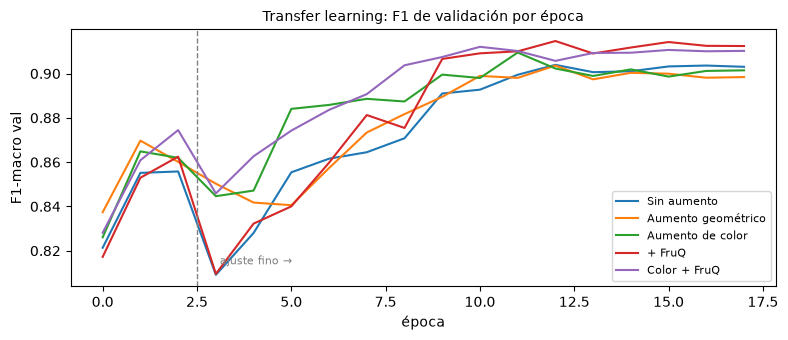

In [13]:
fig, ax = plt.subplots(figsize=(8, 3.5))
for i, n in enumerate(TL_NAMES):
    h = pd.read_csv(config.LOGS_DIR / f"tl_busqueda_{i}_historia.csv")
    ax.plot(h["val_f1_macro"], label=n, lw=1.5)
ax.axvline(transfer.TRANSFER_DEFAULT["head_epochs"] - 0.5, color="grey", ls="--", lw=1)
ax.text(transfer.TRANSFER_DEFAULT["head_epochs"], ax.get_ylim()[0] + 0.01, " ajuste fino →", fontsize=8, color="grey")
ax.set_xlabel("época")
ax.set_ylabel("F1-macro val")
ax.legend(fontsize=8)
ax.set_title("Transfer learning: F1 de validación por época", fontsize=10)
plt.tight_layout()

### Generalización entre fuentes (`tl_entre_fuentes`)

Se entrena **sin** una fuente y se valida solo con sus imágenes de val: mide el cambio de dominio
sin gastar test ni las fotos propias.

In [14]:
LSO_NAMES = ["CNN", "CNN", "TL", "TL", "TL + color", "TL + color", "TL + color + FruQ", "TL + color + FruQ"]
lso = []
for i, n in enumerate(LSO_NAMES):
    r = load_run(f"tl_entre_fuentes_{i}")
    lso.append({"modelo": n, "fuente no vista": r["configuracion"]["holdout"], "F1 (mejor época)": r["val"]["f1_macro"],
                "media últimas 5": r["f1_val_ultimas_5_media"], "recall Podrida": r["val"]["por_clase"]["Podrida"]["recall"]})
pd.DataFrame(lso).pivot(index="modelo", columns="fuente no vista").reindex(list(dict.fromkeys(LSO_NAMES)))

F1 (mejor época)        media últimas 5         \
fuente no vista                hdf kaggle             hdf kaggle   
modelo                                                             
CNN                          0.485  0.364           0.427  0.095   
TL                           0.578  0.417           0.538  0.173   
TL + color                   0.583  0.495           0.577  0.158   
TL + color + FruQ            0.606  0.474           0.500  0.180   

                  recall Podrida         
fuente no vista              hdf kaggle  
modelo                                   
CNN                        0.810  0.135  
TL                         0.343  0.561  
TL + color                 0.283  0.614  
TL + color + FruQ          0.426  0.673

- En las fuentes conocidas, empate: todas las variantes quedan a ±0,01 de la CNN.
- Entre fuentes, el transfer learning mejora (+0,11 a +0,13 validando en Kaggle) y el aumento de
  color es lo que más aporta; FruQ sube el recall de Podrida en la fuente no vista.
- **Elegido `tl_busqueda_4`** (color + FruQ, `config.FINAL_TRANSFER`), fijado antes de mirar test o
  las fotos propias. Resultado final: test F1 0,85; fotos propias 0,47 (`05_evaluation` §6).

## 8. Tercera iteración: reentrenar con etiquetas revisadas (`v3`)

Hipótesis: el ruido en las etiquetas (fotos con varias frutas, frontera Defectuosa/Podrida) explica
los errores con fruta real. Se revisaron las etiquetas (`02_preprocessing` §8) y se reentrenaron
desde cero los dos modelos finales con la **misma configuración** (búsqueda `v3`).

Su F1 de validación usa las etiquetas revisadas, así que **no se compara directamente** con el de
arriba: la comparación justa (mismas imágenes, ambos juegos de etiquetas, y fotos propias) está en
`05_evaluation` §6.

In [15]:
pd.DataFrame([run_row("cnn_estable_1", "CNN · etiquetas originales"), run_row("v3_0", "CNN · etiquetas v3"),
              run_row("tl_busqueda_4", "Transfer · etiquetas originales"), run_row("v3_1", "Transfer · etiquetas v3")]
             ).set_index("configuración")

,épocas,mejor época,F1 train,F1 val,media últimas 5,recall Podrida val,parámetros,minutos
configuración,,,,,,,,
CNN · etiquetas originales,40,30,0.906,0.913,0.890,0.942,340963,4.7
CNN · etiquetas v3,40,36,0.856,0.761,0.757,0.558,340963,3.7
Transfer · etiquetas originales,18,11,0.914,0.912,0.910,0.950,4053414,14.7
Transfer · etiquetas v3,18,15,0.875,0.826,0.824,0.602,4053414,13.5


**Resultado negativo:** con las fotos propias la CNN v3 empeora (0,49 → 0,38, IC sin cero) y el
transfer v3 no mejora de forma demostrable (0,47 → 0,52). La revisión hizo Podrida más exigente
(κ = 0,29 con la re-anotación anterior): el problema es la definición de la clase.

## 9. Cuarta iteración: solo manzana, banano y naranja (`v4`)

Transfer final (color + FruQ) entrenado y validado **solo con 3 frutas** (`config.V4_FRUITS`), donde el
daño contrasta con la piel: `v4_0` con etiquetas originales y `v4_1` con etiquetas v4 (revisión v3 +
regla del banano). La validación tiene solo 3 frutas, así que tampoco se compara con las de arriba.

In [16]:
pd.DataFrame([run_row("v4_0", "3 frutas · etiquetas originales"), run_row("v4_1", "3 frutas · etiquetas v4")]
             ).set_index("configuración")

,épocas,mejor época,F1 train,F1 val,media últimas 5,recall Podrida val,parámetros,minutos
configuración,,,,,,,,
3 frutas · etiquetas originales,18,12,0.872,0.935,0.925,0.912,4053414,6.9
3 frutas · etiquetas v4,18,17,0.824,0.906,0.903,0.865,4053414,6.5


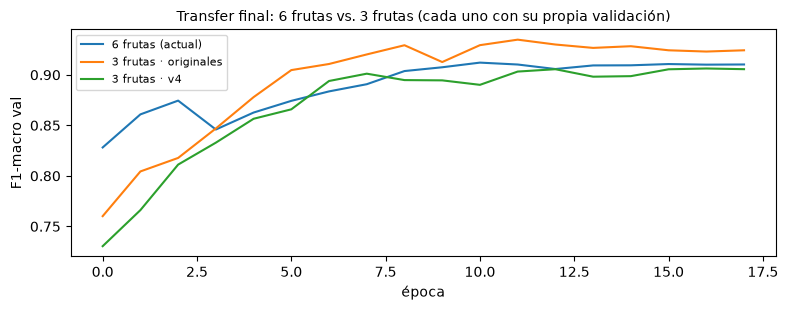

In [17]:
fig, ax = plt.subplots(figsize=(8, 3.2))
for name, label in [("tl_busqueda_4", "6 frutas (actual)"), ("v4_0", "3 frutas · originales"), ("v4_1", "3 frutas · v4")]:
    ax.plot(pd.read_csv(config.LOGS_DIR / f"{name}_historia.csv")["val_f1_macro"], label=label, lw=1.5)
ax.set_xlabel("época")
ax.set_ylabel("F1-macro val")
ax.legend(fontsize=8)
ax.set_title("Transfer final: 6 frutas vs. 3 frutas (cada uno con su propia validación)", fontsize=10)
plt.tight_layout()

Resultado con fotos (`05_evaluation` §7): con 35 fotos nuevas los tres modelos detectan como dañadas
5–6 de 6 podridas; con las 62 fotos anteriores de esas frutas, recortar el alcance sube el recall de
Podrida de 0,30 a 0,48 (IC sin cero). Mejora de **alcance**, modesta. **Decisión del equipo:** se
mantiene `tl_busqueda_4` como modelo de la app (6 frutas); `v4` queda como experimento documentado.

## 10. Todos los entrenamientos

Cada configuración entrenada en el proyecto, con el índice y las frutas que usó. El F1 de validación
solo es comparable **dentro** de un mismo índice y conjunto de frutas.

In [18]:
SEARCH_INFO = {"cnn_busqueda": "1.ª · CNN (CPU)", "cnn_estable": "1.ª · CNN estable (Colab)",
               "tl_busqueda": "2.ª · transfer", "tl_entre_fuentes": "2.ª · entre fuentes",
               "v3": "3.ª · etiquetas revisadas", "v4": "4.ª · 3 frutas"}
all_runs = []
for search, label in SEARCH_INFO.items():
    for path in sorted(config.RESULTS_DIR.glob(f"{search}_[0-9]*.json"), key=lambda p: int(p.stem.rsplit("_", 1)[1])):
        r = json.load(open(path, encoding="utf-8"))
        c = r["configuracion"]
        all_runs.append({"iteración": label, "nombre": path.stem, "modelo": c.get("modelo", "cnn"),
                         "índice": c.get("indice") or "original", "frutas": len(c.get("frutas") or []) or 6,
                         "fuente no vista": c.get("holdout") or "—", "FruQ": bool(c.get("extra")),
                         "aumento": c.get("augment"), "F1 val": r["val"]["f1_macro"],
                         "media últimas 5": r.get("f1_val_ultimas_5_media"), "minutos": r.get("minutos"),
                         "dispositivo": r.get("dispositivo", "CPU")})
all_runs = pd.DataFrame(all_runs).set_index("nombre")
final = {config.FINAL_MODEL: "CNN final", config.FINAL_TRANSFER: "app"}
all_runs["elegido"] = all_runs.index.map(final).fillna("")
print(len(all_runs), "entrenamientos ·", round(all_runs["minutos"].sum()), "minutos registrados (la búsqueda 1 en CPU no guardaba la duración)")
all_runs

26 entrenamientos · 181 minutos registrados (la búsqueda 1 en CPU no guardaba la duración)


,iteración,modelo,índice,frutas,fuente no vista,FruQ,aumento,F1 val,media últimas 5,minutos,dispositivo,elegido
nombre,,,,,,,,,,,,
cnn_busqueda_0,1.ª · CNN (CPU),cnn,original,6,—,False,True,0.867,NaN,NaN,CPU,
cnn_busqueda_1,1.ª · CNN (CPU),cnn,original,6,—,False,False,0.891,NaN,NaN,CPU,
cnn_busqueda_2,1.ª · CNN (CPU),cnn,original,6,—,False,True,0.846,NaN,NaN,CPU,
cnn_busqueda_3,1.ª · CNN (CPU),cnn,original,6,—,False,True,0.814,NaN,NaN,CPU,
cnn_busqueda_4,1.ª · CNN (CPU),cnn,original,6,—,False,True,0.857,NaN,NaN,CPU,
cnn_estable_0,1.ª · CNN estable (Colab),cnn,original,6,—,False,True,0.876,0.870,9.4,GPU,
cnn_estable_1,1.ª · CNN estable (Colab),cnn,original,6,—,False,False,0.913,0.890,4.7,GPU,CNN final
cnn_estable_2,1.ª · CNN estable (Colab),cnn,original,6,—,False,True,0.881,0.879,9.3,GPU,
cnn_estable_3,1.ª · CNN estable (Colab),cnn,original,6,—,False,True,0.890,0.884,9.0,GPU,
